In [21]:
import re
import unicodedata
from pathlib import Path
from collections import defaultdict, Counter
import pandas as pd
import numpy as np
import rasterio
import zipfile
import io
import json
import matplotlib.pyplot as plt

IN_FILE  = Path("datasets/resultset.xlsx")
OUT_FILE = Path("datasets/fineli_head_medians.xlsx")
HEAD_FINELLI_NO_LEMMATIZATION = Path("datasets/fineli_head_medians_no_lemmatization.xlsx")
NUMBERS_FILE = Path("datasets/fineli_pre_processed.xlsx")

# Note: zip files are not in git, download them independently and add them to the directory manually
# Source for this zip: https://drive.google.com/file/d/1Dmnco2Bmm--AGRcdxlFaOXOF3K1d2PzK/view?usp=sharing
SUOMI24_CORPUS_01_06_ZIP_PATH = Path("corpus_files/Parsed_data_1_6.zip")
BATCH_SIZE = 500

LESS_THAN_REPLACEMENT_VALUE = 0.05  # "<0.1" is treated as 0.05

In [2]:
def to_number(value):
    """'12.5' -> 12.5, '<0.1' -> 0.05, 'N/A' or empty -> NaN"""
    if pd.isna(value):
        return np.nan
    value = str(value).strip().replace(',', '.')  # In case '12,5' -> '12.5'
    if value.upper() in {'N/A', 'NA', '-', ''}:
        return np.nan
    if value.startswith('<'):  # '<0.1' -> '0.05'
        return LESS_THAN_REPLACEMENT_VALUE
    try:
        return float(value)
    except ValueError:
        return np.nan


def head_term(name):
    """'Ahven, paistettu voissa' -> 'ahven'"""
    head = str(name).split(',')[0]  # text before the first comma
    head = head.split('/')[0]  # first alternative only, 'Aromisuola/yrttisuola 71 %' -> 'aromisuola'
    head = re.split(r'\d', head)[0]  # cut at the first number, 'kasvirasvalevite 70 %' -> 'kasvirasvalevite'
    head = unicodedata.normalize('NFC', head)  # consistent å/ä/ö for later matching
    head = re.sub(r'\s+', ' ', head).strip().lower()  # replace multiple whitespaces with single whitespaceS
    return head

In [3]:
from simplemma import Lemmatizer
from simplemma.strategies import DictionaryLookupStrategy
from simplemma.strategies.dictionaries import DefaultDictionaryFactory

lemmatizer = Lemmatizer(
    lemmatization_strategy=DictionaryLookupStrategy(dictionary_factory=DefaultDictionaryFactory())
)


def lemmatize_word(word):
    """'ahvenet' -> 'ahven'"""
    if not word:
        return word
    return lemmatizer.lemmatize(word, lang='fi').lower()


def lemmatize_term(term):
    """'ahvenet foliossa' -> 'ahven folio', 'ateria-ainekset' -> 'ateria-aines'"""
    return ' '.join('-'.join(lemmatize_word(part) for part in word.split('-'))
                    for word in term.split(' '))

print(lemmatize_term('ahvenet foliossa'))  # expect: ahven folio
print(lemmatize_term('herneet'))  # expect: herne
print(lemmatize_term('ateria-ainekset'))  # check how the hyphen is handled (expect: ateria-aines)

ahven folio
herne
ateria-aines


In [4]:
def read_fineli_raw(in_file):
    return pd.read_excel(in_file, dtype=str)

def convert_to_numbers(raw):
    nutrient_cols = [c for c in raw.columns if c not in ('id', 'name')]
    numbers = raw.copy()
    numbers[nutrient_cols] = raw[nutrient_cols].apply(lambda col: col.map(to_number))
    return numbers

def calculate_medians(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    df = df[df['name'] != '']

    lemma_map = {head: lemmatize_term(head) for head in df['name'].unique()}
    df['name'] = df['name'].map(lemma_map)

    return df.groupby('name').median()

def calculate_medians_no_lemmatization(numbers):
    df = numbers.drop(columns='id')
    df['name'] = df['name'].map(head_term)
    return df.groupby('name').median()

def load_fineli_dataset(in_file=IN_FILE, numbers_file=NUMBERS_FILE, out_file=OUT_FILE):
    raw = read_fineli_raw(in_file)

    numbers = convert_to_numbers(raw)
    # numbers.to_excel(numbers_file, index=False)

    medians = calculate_medians(numbers)
    medians.to_excel(out_file)
    return medians

In [13]:
fineli = load_fineli_dataset()
print("\n", fineli)

# Creating a set for fast lookups for thread retrieval
fineli_lemmas = set(fineli.index) # Grabs the names which have already been lemmatized
# This one is for faster lookups as well
fineli_dict = fineli[~fineli.index.duplicated(keep='first')].to_dict('index')

C:\Users\Martt\AppData\Roaming\Python\Python312\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")



                     energia, laskennallinen (kJ)  rasva (g)  \
name                                                          
ahven                                 597.447244   6.642549   
ahven folio                           495.981167   4.080596   
amarantti                            1545.439941   7.000000   
ananas                                270.299995   0.306000   
ananassalsa                           208.769466   0.358155   
...                                          ...        ...   
wokattu kasvis                        362.226265   6.849243   
yrtti                                 108.538630   0.513268   
yrttilevite                          1589.106688  40.113636   
äidinmaidonkorvike                   1180.312120  14.262000   
äidinmaito                            273.049988   3.495000   

                    hiilihydraatti imeytyvä (g)  proteiini (g)  alkoholi (g)  \
name                                                                           
ahven             

In [16]:

def loadSuomi24Corpus(path):
    """More like instantiate the shit"""
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        n=24
        for i, line in enumerate(f):
            if i >= n:
                break
            print(line)

def retrieve_threads_and_messages(path):
    """
    Retrieve threads and messages from suomi24 dataset by using fineli dataset.
    Return messages and threads where match was found. Return also date.
    Splitting threads to batches to avoid RAM abuse in these trying times
    Parameter requires a zip file of the data
    """
    with zipfile.ZipFile(path, 'r') as z:
        # Assumed structure: .zip file -> "Parsed_data" directory -> enumerated directories with 4 .txt files each
        txt_files = [
            f for f in z.namelist() if f.endswith("with_comments.txt")
        ]

        for file in txt_files:
            print(f"Processing file {file}")
            with z.open(file) as file_bytes:
                with io.TextIOWrapper(file_bytes, encoding="utf-8") as text_file:
                    batch = []

                    for line in text_file:
                        data = line.strip()
                        if not data:
                            continue

                        try:
                            data_dict = json.loads(line)

                            thread_bundle = {
                                "title": data_dict.get("title"),
                                "date": data_dict.get("date"),
                                "orig_msg": data_dict.get("orig_msg"),
                                "orig_msg_lemmatized": data_dict.get("orig_msg_lemmatized"),
                                "comment_lemmas": []
                            }
                            
                            thread_words_set = set()

                            if thread_bundle["orig_msg_lemmatized"]:
                                thread_words_set.update(
                                    word for word in thread_bundle["orig_msg_lemmatized"]
                                )

                            comments_array = data_dict.get("comments", [])
                            for comment in comments_array:
                                c_lemmas = comment.get("orig_msg_lemmatized") 
                                if c_lemmas:
                                    thread_bundle["comment_lemmas"].append(c_lemmas)
                                    thread_words_set.update(
                                        word.lower() for word in c_lemmas
                                    )
                            

                            if thread_words_set.isdisjoint(fineli_lemmas):
                                # No matches found within the thread, continuing to next thread
                                continue

                            batch.append(thread_bundle)
                            
                        except json.JSONDecodeError as e:
                            print(f"Somehow the file wasnt valid JSON???? {e}")
                            continue

                        if len(batch) >= BATCH_SIZE:
                            count_monthly_nutrition_intake(batch)
                            batch = []

                    if batch:
                        count_monthly_nutrition_intake(batch)



monthly_nutrition = defaultdict(Counter)
def count_monthly_nutrition_intake(batch):
    """
    Count montly intake evolution of calories on foods, saving result to global tracker due to batch based approach
    """
    for thread in batch:
        date_string = thread.get("date")
        try:
            month_key = str(date_string)[:7]
        except Exception:
            # Should never happen, corpus seems to reliably include date
            month_key = None
    
        thread_words = set()
        title = thread.get("orig_msg_lemmatized")
        if title:
            thread_words.update(title)
        for comment_lemma in thread.get("comment_lemmas"):
            thread_words.update(comment_lemma)

        matched_foods = thread_words.intersection(fineli_lemmas)
        for food in matched_foods:
            nutrient_data = fineli_dict[food]
            monthly_nutrition[month_key].update(nutrient_data)
        


import re

"""<text comment_id="0" date="2001-01-01" datetime="2001-01-01 01:30:00" author="Honda" parent_comment_id="0" quoted_comment_id="0" author_logged_in="n" nick_type="anonymous" thread_id="19455" time="01:30:00" title="Hyvää uutta vuotta kaikille Hondailijoille" topic_nums="3258,1109,6254,2" msg_type="thread_start" topic_name_leaf="Honda" topic_name_top="Ajoneuvot ja liikenne" topic_names="Ajoneuvot ja liikenne &gt; Autot &gt; Automerkit &gt; Honda" topic_names_set="|Ajoneuvot ja liikenne|Automerkit|Autot|Honda|" topic_nums_set="|1109|2|3258|6254|" topic_adultonly="n" datefrom="20010101" dateto="20010101" timefrom="013000" timeto="013000" id="19455:0" author_v1="Honda" author_name_type="user_nickname" author_nick_registered="n" author_signed_status="0" thread_start_datetime="2001-01-01 01:30:00" filename_vrt="s24_2001_01.vrt" parent_datetime="" datetime_approximated="n" empty="n" filename_orig="threads2003a.vrt" origfile_textnum="17841">"""

def parse_text_line(line):
    temp = line.replace('<text', "")
    temp = temp.replace('>',"")
    temp = temp.replace('\n', "")
    temp = temp.split('"')
    jiisonni = {}
    for index in temp:
        if "=" in index:
            temp =  index.strip().replace("=","")
            #jiisonni[temp] = 
    print(temp)

    
def dataset_parser(path):
    """Parses data from the dataset and puts it into a json file and maybe database later."""
    with open(path, "r", encoding="utf-8",errors="replace") as f:
        for line in f:
            if line.startswith("<text"):
                temp_list = line.split(" ")
                temp_values = re.findall('"([^"]*)"', line)
                parse_text_line(line)
                for index in temp_list:
                    print(temp_values)
                    """  
                    thread_json = {
                    thread_id:,
                    topic:,
                    date:,
                    title:,
                    message:,
                    lemmatized_message:,
                    comments:{
                        comment_title:,
                        comment_text:,
                        date:
                    }
                    }
                    """
                    exit()
            if line.startswith("<paragraph"):
                temp_line = line.split(" ")
                if temp_line:
                    pass



#dataset_parser("datasets/s24_2001.vrt")

#print("Exiting..")
#exit()







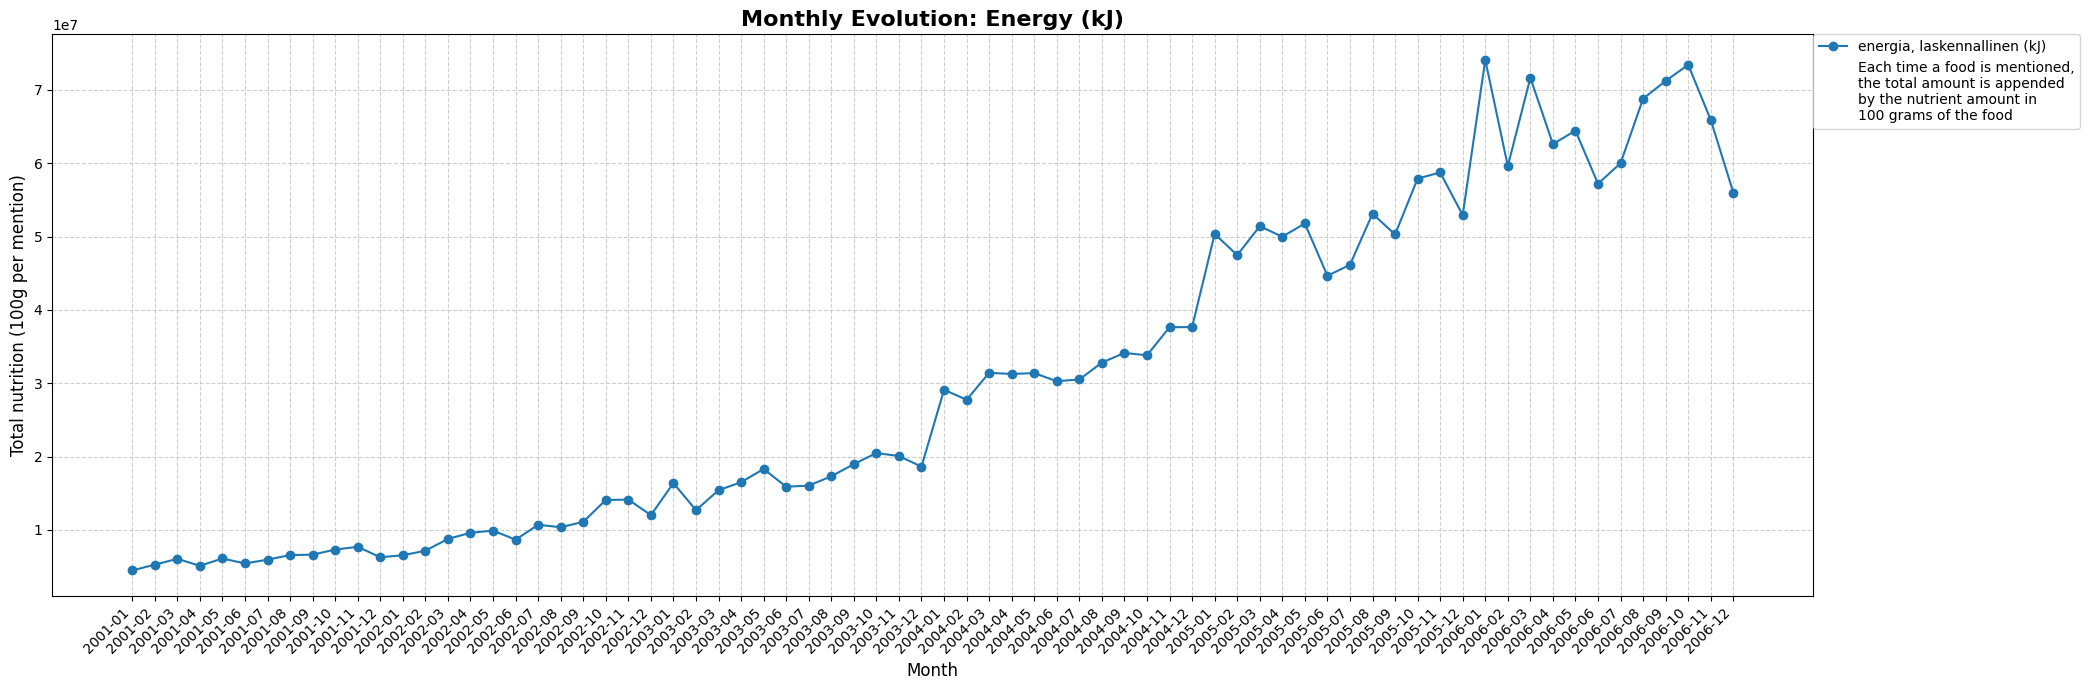

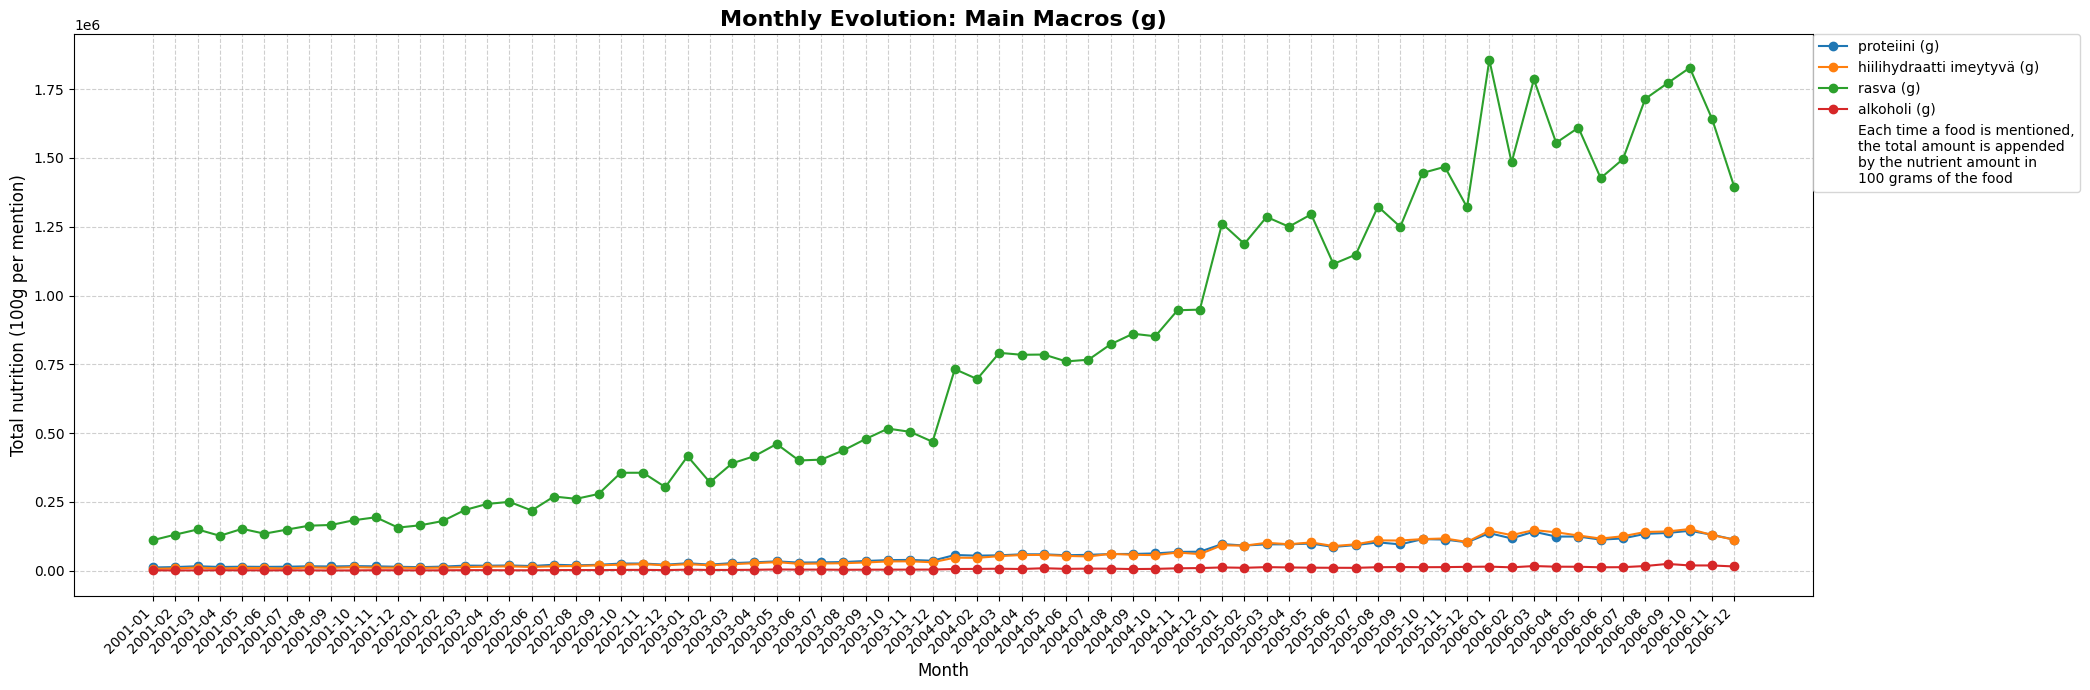

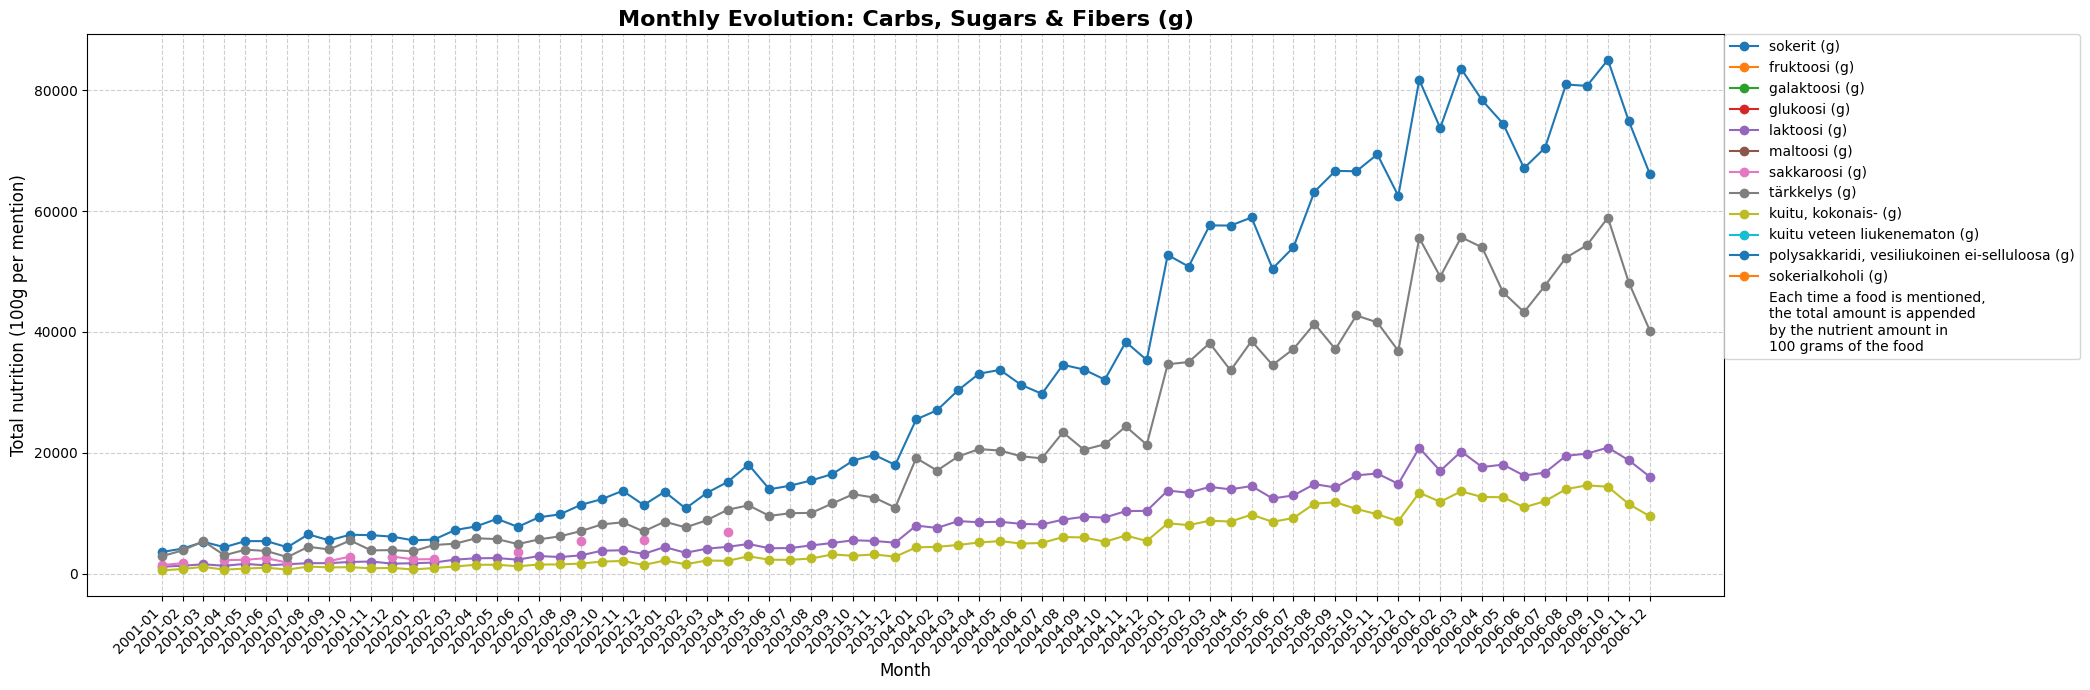

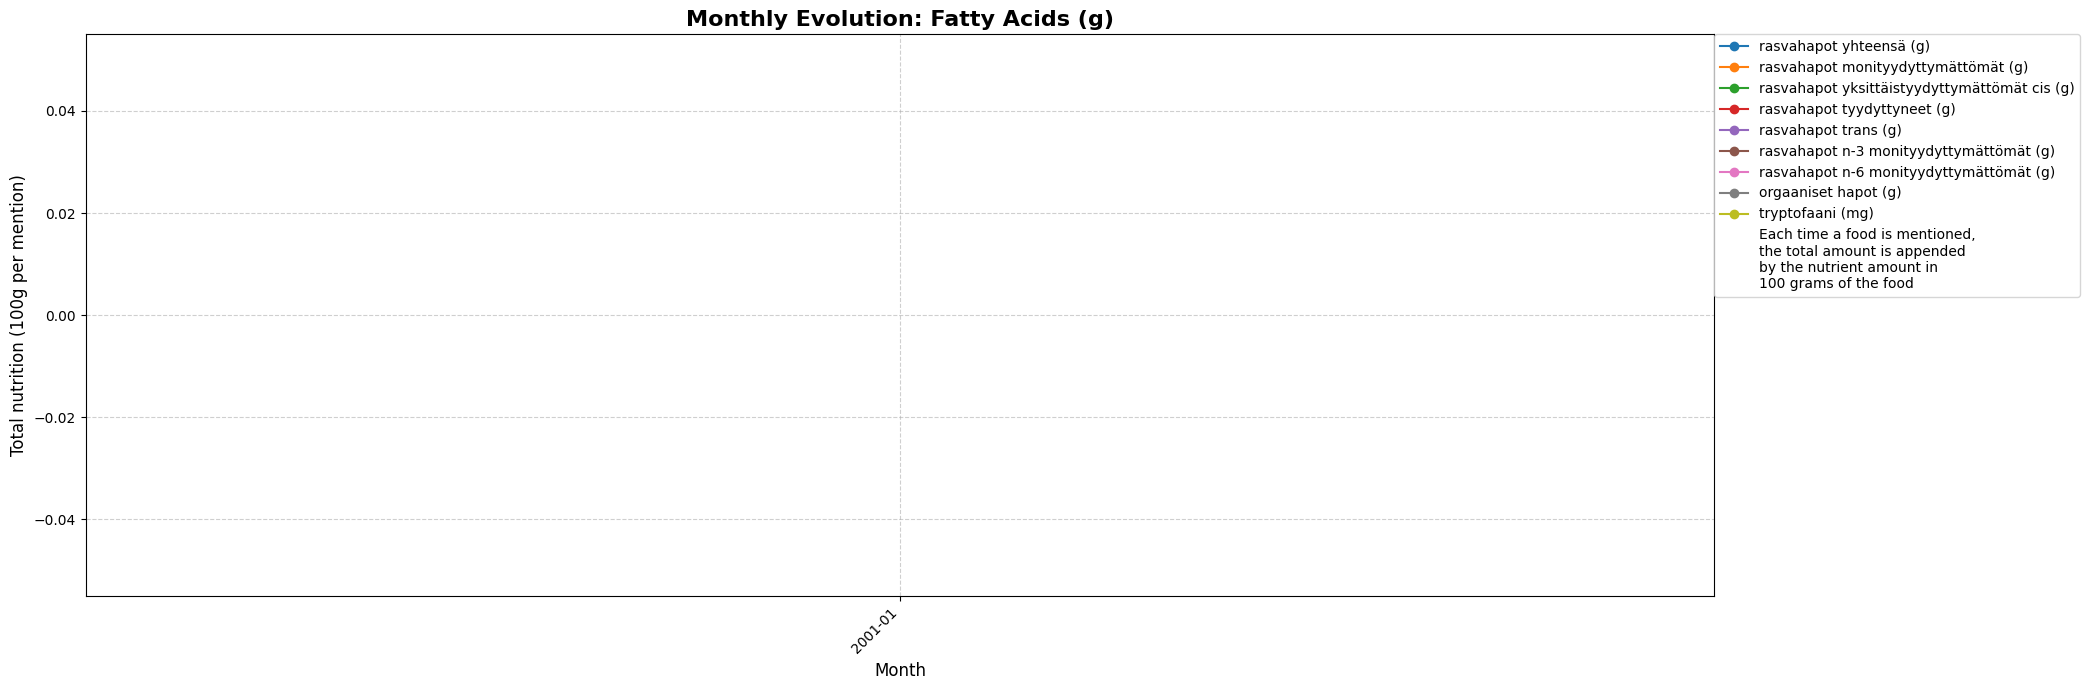

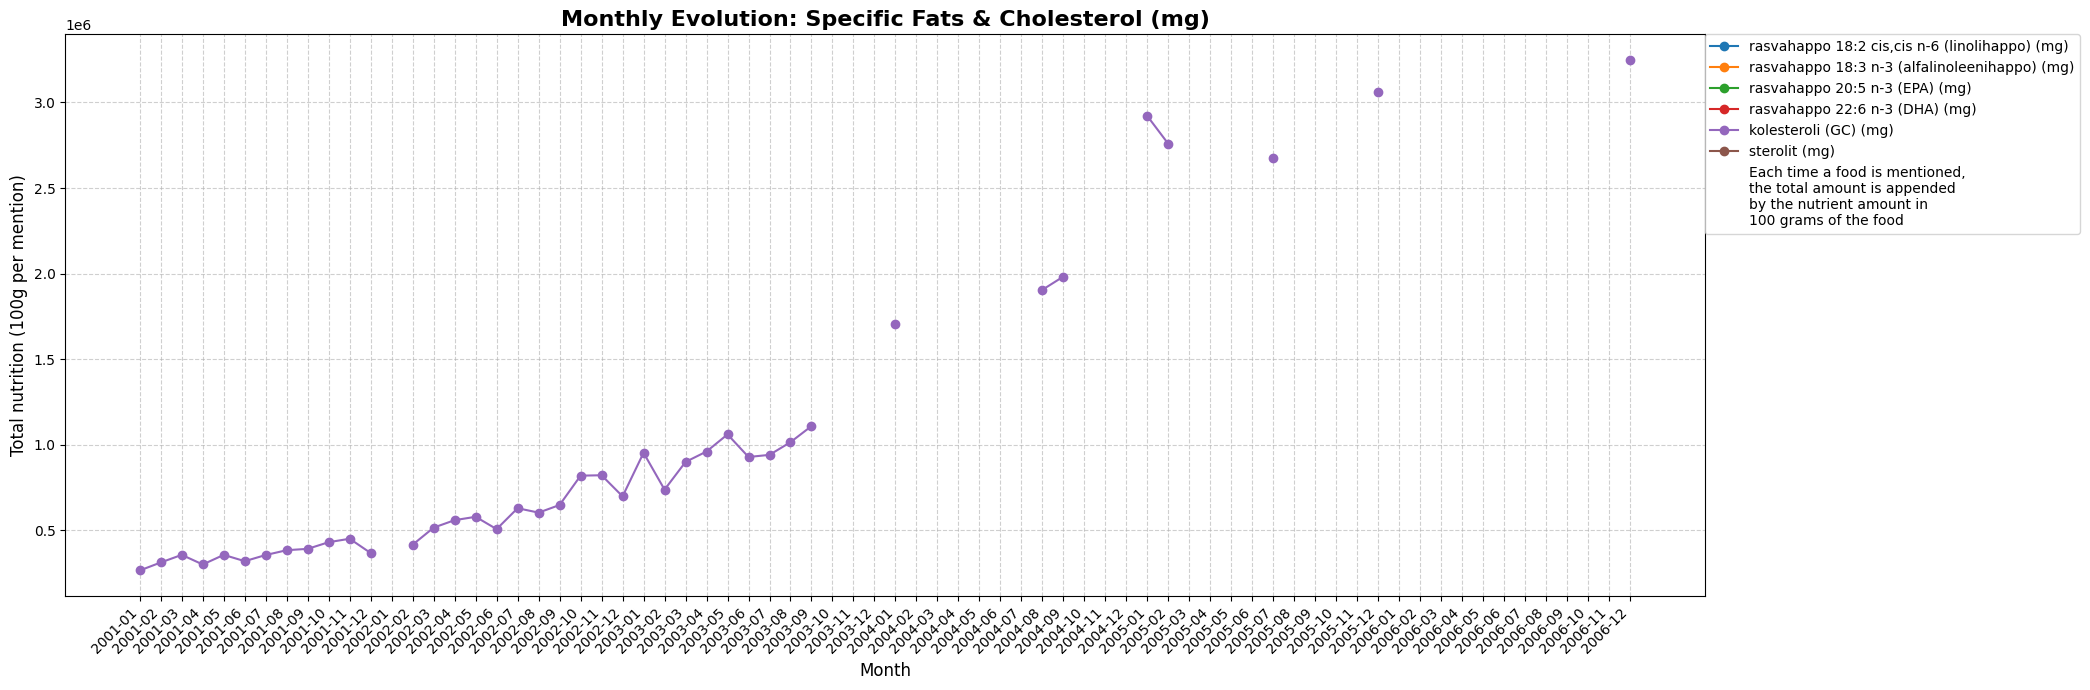

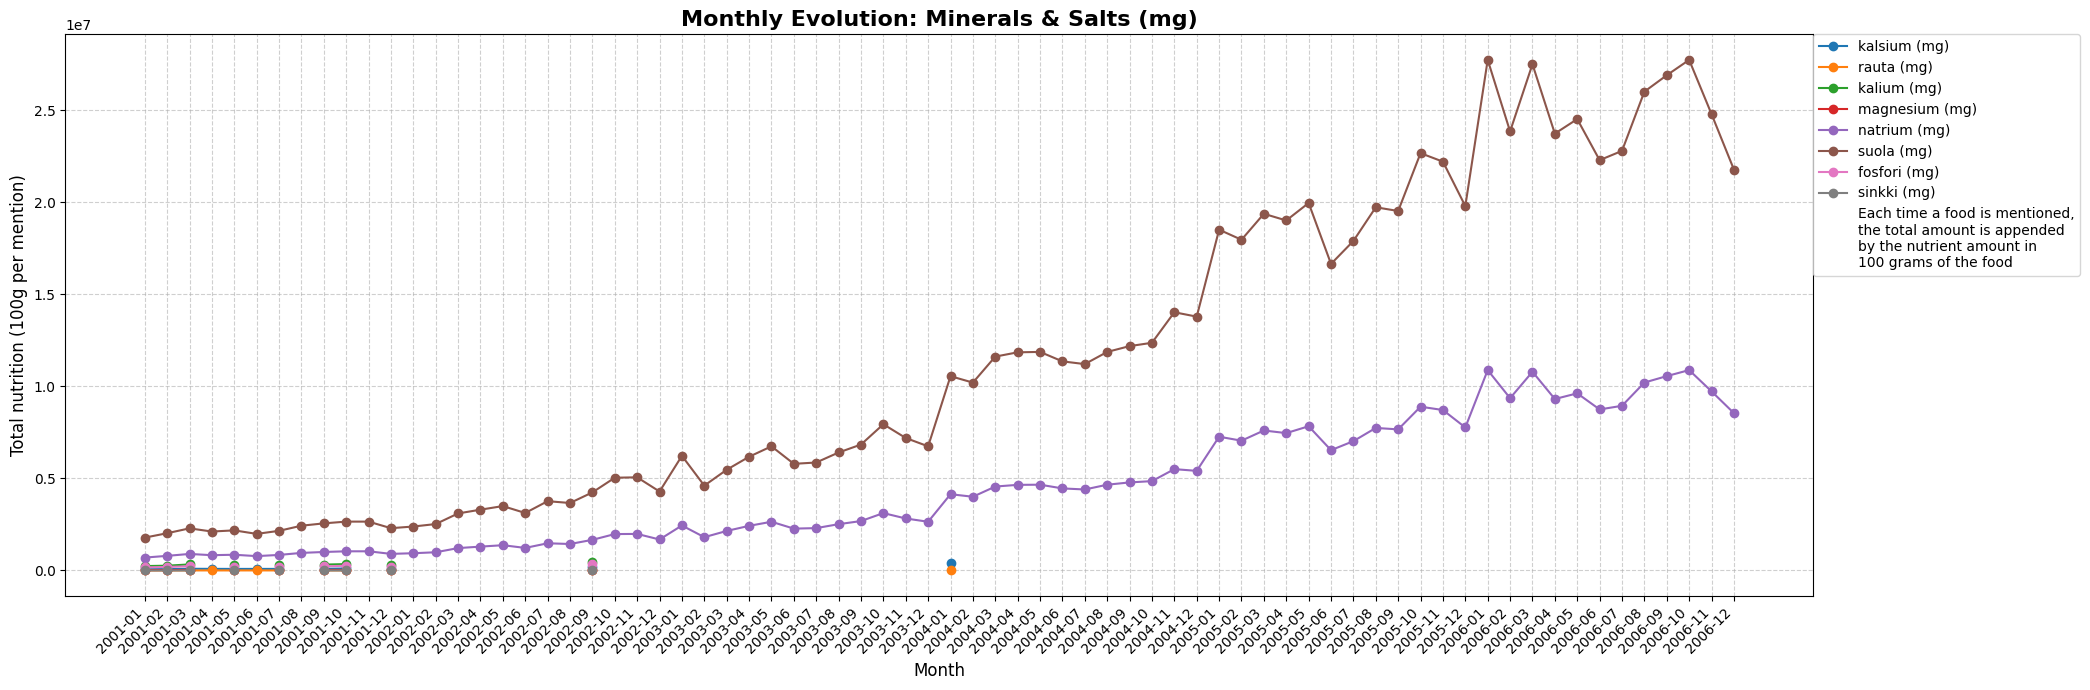

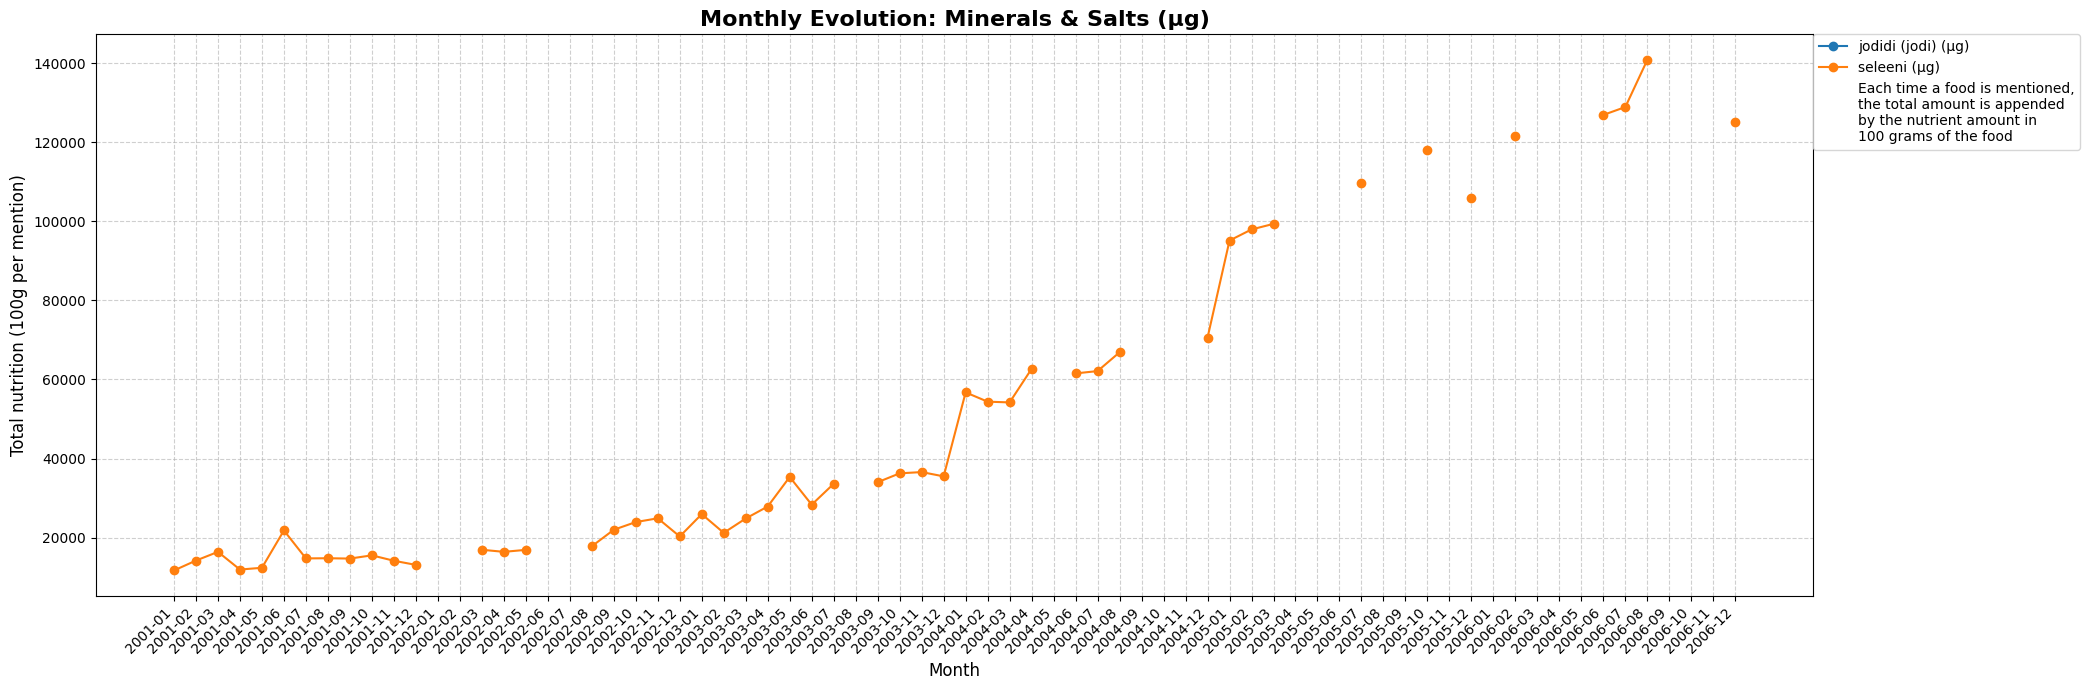

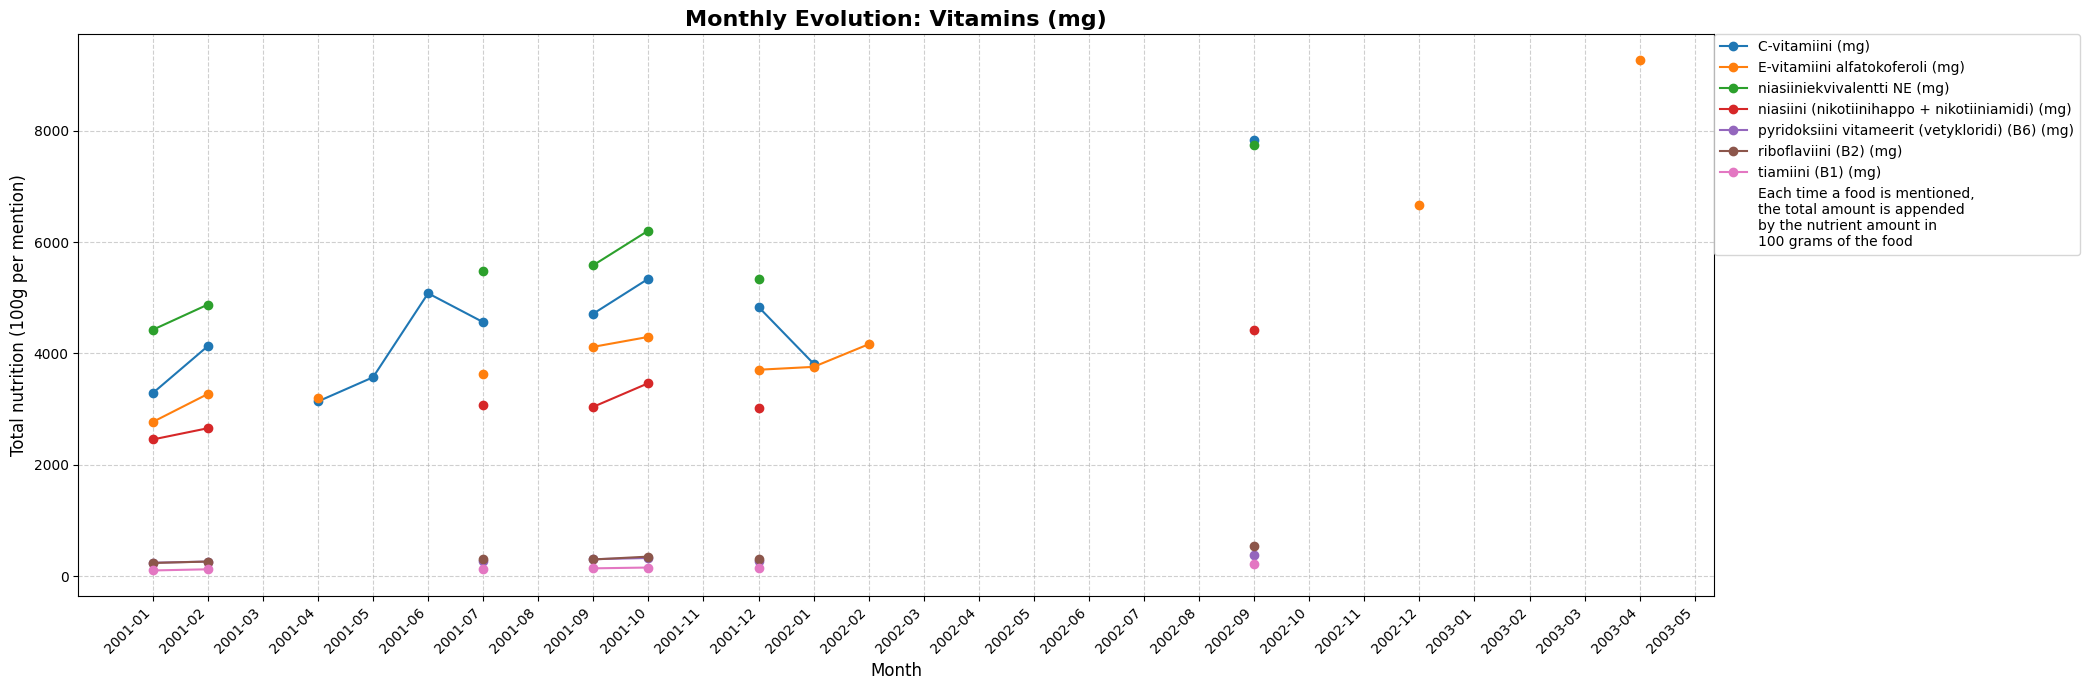

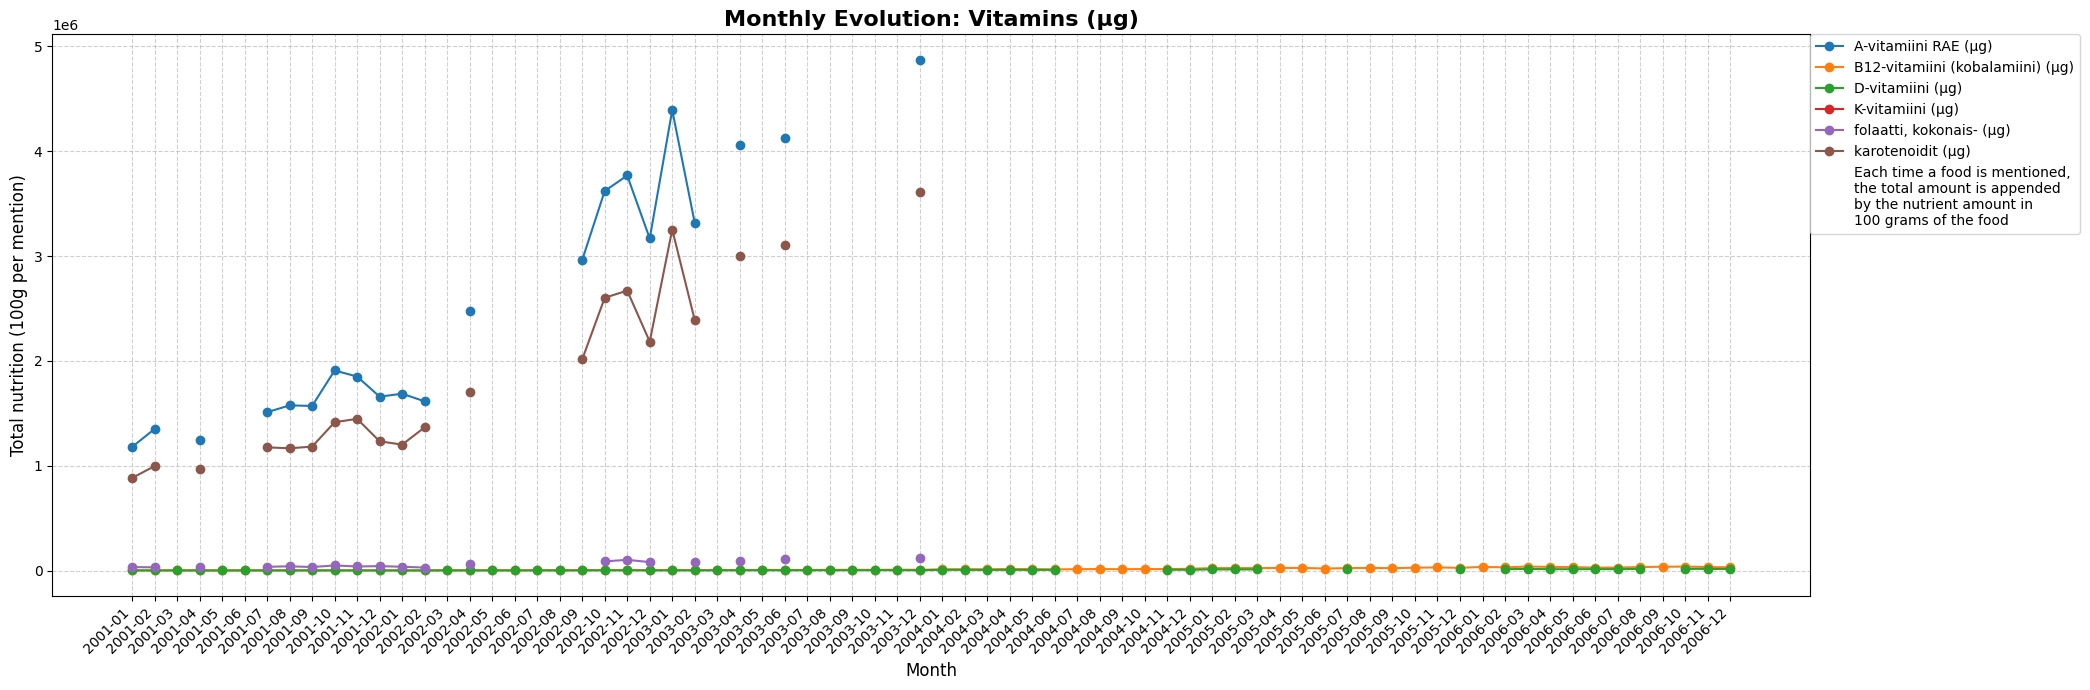

In [34]:

#retrieve_threads_and_messages(SUOMI24_CORPUS_01_06_ZIP_PATH)
def draw_monthly_nutrition_intake():
    """
    Draw montly intake evolution of calories on foods
    Access numerical data from monthly_nutrition
    """
    final_results_df = pd.DataFrame.from_dict(monthly_nutrition, orient='index')
    final_results_df.index.name = 'Month'
    final_results_df = final_results_df.sort_index()

    final_results_df.index = final_results_df.index.astype(str)

    nutrient_groups = {
        "Energy (kJ)": [
            'energia, laskennallinen (kJ)'
        ],
        "Main Macros (g)": [
            'proteiini (g)', 'hiilihydraatti imeytyvä (g)', 'rasva (g)', 'alkoholi (g)'
        ],
        "Carbs, Sugars & Fibers (g)": [
            'sokerit (g)', 'fruktoosi (g)', 'galaktoosi (g)', 'glukoosi (g)', 
            'laktoosi (g)', 'maltoosi (g)', 'sakkaroosi (g)', 'tärkkelys (g)', 
            'kuitu, kokonais- (g)', 'kuitu veteen liukenematon (g)', 
            'polysakkaridi, vesiliukoinen ei-selluloosa (g)', 'sokerialkoholi (g)'
        ],
        "Fatty Acids (g)": [
            'rasvahapot yhteensä (g)', 'rasvahapot monityydyttymättömät (g)', 
            'rasvahapot yksittäistyydyttymättömät cis (g)', 'rasvahapot tyydyttyneet (g)', 
            'rasvahapot trans (g)', 'rasvahapot n-3 monityydyttymättömät (g)', 
            'rasvahapot n-6 monityydyttymättömät (g)', 'orgaaniset hapot (g)', 'tryptofaani (mg)'
        ],
        "Specific Fats & Cholesterol (mg)": [
            'rasvahappo 18:2 cis,cis n-6 (linolihappo) (mg)', 
            'rasvahappo 18:3 n-3 (alfalinoleenihappo) (mg)', 
            'rasvahappo 20:5 n-3 (EPA) (mg)', 'rasvahappo 22:6 n-3 (DHA) (mg)', 
            'kolesteroli (GC) (mg)', 'sterolit (mg)'
        ],
        "Minerals & Salts (mg)": [
            'kalsium (mg)', 'rauta (mg)', 'kalium (mg)', 'magnesium (mg)',
            'natrium (mg)', 'suola (mg)', 'fosfori (mg)', 'sinkki (mg)'
        ],
        "Minerals & Salts (µg)": [
            'jodidi (jodi) (µg)','seleeni (µg)',
        ],
        "Vitamins (mg)": [ 
            'C-vitamiini (mg)', 'E-vitamiini alfatokoferoli (mg)', 
            'niasiiniekvivalentti NE (mg)', 
            'niasiini (nikotiinihappo + nikotiiniamidi) (mg)', 
            'pyridoksiini vitameerit (vetykloridi) (B6) (mg)', 
            'riboflaviini (B2) (mg)', 'tiamiini (B1) (mg)'
        ],
        "Vitamins (µg)": [
            'A-vitamiini RAE (µg)', 'B12-vitamiini (kobalamiini) (µg)', 
            'D-vitamiini (µg)', 'K-vitamiini (µg)', 'folaatti, kokonais- (µg)',
            'karotenoidit (µg)'
        ]
    }

    for group_name, columns in nutrient_groups.items():
        valid_cols = [col for col in columns if col in final_results_df.columns]
    
        if not valid_cols:
            print(f"Skipping {group_name} because none of those columns exist in the dataframe.")
            continue

        plt.figure(figsize=(21, 7))
    
        for col in valid_cols:
            plt.plot(final_results_df.index, final_results_df[col], marker='o', label=col)
    
        plt.title(f"Monthly Evolution: {group_name}", fontsize=16, fontweight='bold')
        plt.xlabel("Month", fontsize=12)
        plt.ylabel("Total nutrition (100g per mention)", fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.plot([], [], ' ', label="Each time a food is mentioned,\nthe total amount is appended\nby the nutrient amount in\n100 grams of the food")
        plt.legend(loc='upper left', bbox_to_anchor=(1, 1), borderaxespad=0.)
    
        plt.grid(True, linestyle='--', alpha=0.6)
        
    
        plt.tight_layout()
        plt.show()

draw_monthly_nutrition_intake()